<a href="https://colab.research.google.com/github/RachmadAprisandhy/PembelajaranMesin/blob/main/JS08/JS08_Assignment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
path = '/content/drive/MyDrive/Pembelajaran mesin/CC_Customer_Dataset.csv'
data = pd.read_csv(path)

In [5]:
print("Ukuran data:", data.shape)
print("Kolom:", data.columns.tolist())
display(data.head())

Ukuran data: (660, 7)
Kolom: ['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


import library

In [6]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

Buatlah model klasterisasi dengan menggunakan Agglomerative Clustering dengan seluruh variabel yang dapat digunakan.

In [8]:
# Abaikan kolom ID jika ada. Tambahkan nama kolom ID lain bila dataset-mu memilikinya.
id_cols = [
    col for col in data.columns
    if col.lower() in {"id", "clientnum", "customer_id", "customerid"}
]

X = data.drop(columns=id_cols).copy()

numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(exclude="number").columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, numeric_cols),
    ("categorical", categorical_pipe, categorical_cols),
])

X_processed = preprocessor.fit_transform(X)

# AgglomerativeClustering dan silhouette memerlukan representasi dense.
if hasattr(X_processed, "toarray"):
    X_processed = X_processed.toarray()

print("Jumlah fitur setelah preprocessing:", X_processed.shape[1])

Jumlah fitur setelah preprocessing: 7



Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu Avg_Credit_Limit dan Total_credit_card. Tunjukkan bentuk cluster-nya berdasarkan dua fitur tersebut.

In [13]:
from sklearn.cluster import AgglomerativeClustering

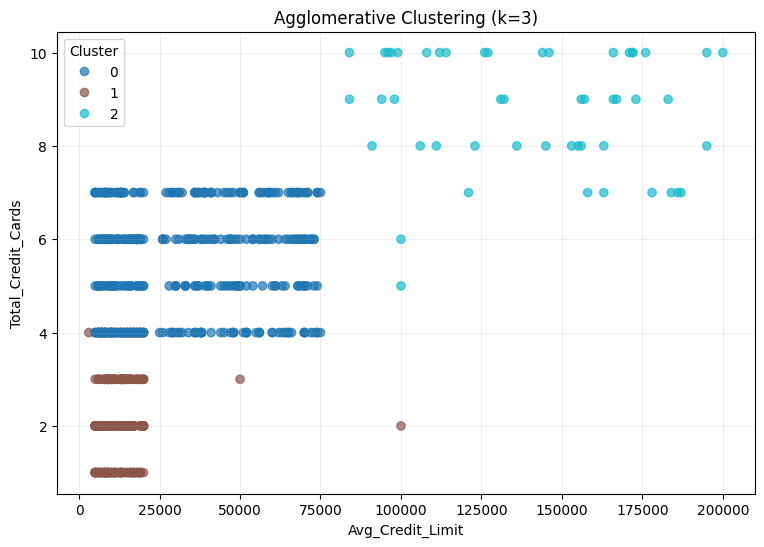

In [16]:
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering

k = 3

kolom_x = "Avg_Credit_Limit"
kolom_y = "Total_Credit_Cards"

model_akhir = AgglomerativeClustering(n_clusters=k, linkage="ward")
data["Cluster"] = model_akhir.fit_predict(X_processed)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    data[kolom_x],
    data[kolom_y],
    c=data["Cluster"],
    cmap="tab10",
    alpha=0.7,
)

plt.xlabel(kolom_x)
plt.ylabel(kolom_y)
plt.title(f"Agglomerative Clustering (k={k})")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.grid(alpha=0.2)
plt.show()

Tentukan nilai silhouette score dan DBI dari model.

In [17]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

labels = data["Cluster"]

silhouette = silhouette_score(X_processed, labels)
dbi = davies_bouldin_score(X_processed, labels)

print(f"Silhouette Score: {silhouette:.4f}")
print(f"DBI: {dbi:.4f}")

Silhouette Score: 0.4439
DBI: 0.8517
